# Relative strength rotation on a halal universe

This backtests a concentrated, high-turnover, monthly-rebalanced, long-only strategy over the
tickers in `equities-list.csv` (rows with `Asset Type == Stock`; the ETFs in that file are
excluded since the strategy ranks individual names against each other). The CSV labels these as
halal *candidates* only — independently verify current Shariah compliance before investing.

**Strategy specification**

1. Every month end, rank the eligible universe by trailing 3-month return.
2. Take the top 10 names, equal-weighted (10% each).
3. Next month: rerank from scratch and rebuild the top 10. A name that falls out of the top 10
   is simply not in next month's portfolio — there's no buffer band keeping it around, unlike the
   pure cross-sectional momentum notebook's top-20%-buy/top-30%-hold rule.

This is a variant on cross-sectional momentum, but more concentrated (10 names instead of ~20% of
the universe) and with a shorter, unskipped lookback (3 months instead of 12-1). Both changes push
in the same direction: a more reactive, higher-turnover portfolio where names enter and leave
naturally from month to month, illustrated below with the kind of roster change you'd actually see:

| September (example) | October (example) |
|---|---|
| NVDA | MU |
| MU | AVGO |
| AMD | TSM |
| AVGO | LLY |
| TSM | XOM |
| ANET | ... |
| LLY | |
| PLTR | |
| AMAT | |
| FANG | |

Daily bars are reused from the other momentum notebooks' shared cache (`data/daily/`) — the
acquisition cell below is identical and simply fetches anything that isn't already cached.

## Before running

1. Install dependencies: `pip install ib-insync pandas numpy matplotlib pandas-datareader`
2. Run IBKR Trader Workstation or IB Gateway, enable API connections, and use a market-data-enabled
   account.
3. Set the host, port, and client ID below. Typical paper ports are 7497 for TWS and 4002 for
   Gateway; live ports are commonly 7496 and 4001.
4. Run the acquisition cell once. It shares the same `data/daily/{TICKER}.csv` cache as the other
   momentum notebooks, so if you've already run one of those, this one has nothing left to fetch.

In [1]:
from pathlib import Path
import csv
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from ib_insync import IB, Stock, util
except ImportError as exc:
    raise ImportError('Install ib-insync first: pip install ib-insync') from exc

EQUITIES_LIST_PATH = Path('equities-list.csv')
DATA_DIR = Path('data') / 'daily'
LOG_PATH = Path('data') / 'daily_download_log.csv'

with open(EQUITIES_LIST_PATH, newline='') as f:
    equities_rows = list(csv.DictReader(f))
UNIVERSE = [row['Ticker'] for row in equities_rows if row['Asset Type'] == 'Stock']
print(f'{len(UNIVERSE)} candidate halal stocks in the universe')

EXCHANGE = 'SMART'
CURRENCY = 'USD'
START_DATE = pd.Timestamp('2009-01-01', tz='UTC')
END_DATE = pd.Timestamp.now(tz='UTC')
BAR_SIZE = '1 day'
DURATION = '20 Y'
WHAT_TO_SHOW = 'TRADES'
USE_RTH = True

IB_HOST = '172.27.224.1'  # '127.0.0.1'
IB_PORT = 7497
IB_CLIENT_ID = 33
PACING_SLEEP_SECONDS = 10.0

# Strategy parameters
LOOKBACK_MONTHS = 3    # trailing return window, in months (no skip month, unlike 12-1 momentum)
TOP_N = 10             # concentrated top-10 roster
MIN_UNIVERSE = 15      # minimum ranked names required before trading a given month

INVESTMENT_2026_DOLLARS = 150.0
TARGET_CPI = None  # leave None to use the latest available CPI reading from FRED

132 candidate halal stocks in the universe


## Download or load the daily bars

Identical acquisition logic to the other momentum notebooks: one IBKR historical data request per
ticker (daily bars support multi-year durations in a single call), cached to
`data/daily/{TICKER}.csv`, skipping anything already cached and logged `ok` in
`data/daily_download_log.csv`.

In [2]:
def normalize_bars(bars):
    frame = util.df(bars)
    if frame is None or frame.empty:
        return pd.DataFrame()
    frame['date'] = pd.to_datetime(frame['date'], utc=True)
    frame = frame.set_index('date').sort_index()
    keep = ['open', 'high', 'low', 'close', 'volume', 'average', 'barCount']
    return frame[[column for column in keep if column in frame.columns]]

def load_cached_bars(ticker):
    frame = pd.read_csv(DATA_DIR / f'{ticker}.csv', parse_dates=['date'], index_col='date')
    frame.index = pd.DatetimeIndex(frame.index).tz_convert('UTC')
    return frame.sort_index()

def download_universe():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    util.patchAsyncio()
    ib = IB()
    ib.connect(IB_HOST, IB_PORT, clientId=IB_CLIENT_ID, readonly=True, timeout=20)

    log_rows = list(csv.DictReader(open(LOG_PATH))) if LOG_PATH.exists() else []
    done = {row['ticker'] for row in log_rows if row['status'] == 'ok'}

    for i, ticker in enumerate(UNIVERSE, 1):
        cache_path = DATA_DIR / f'{ticker}.csv'
        if ticker in done and cache_path.exists():
            continue
        status, n_bars, first_date, last_date, error = 'ok', 0, '', '', ''
        try:
            contract = Stock(ticker, EXCHANGE, CURRENCY)
            qualified = ib.qualifyContracts(contract)
            if not qualified or contract.conId == 0:
                raise RuntimeError('contract could not be qualified')
            bars = ib.reqHistoricalData(
                contract, endDateTime='', durationStr=DURATION,
                barSizeSetting=BAR_SIZE, whatToShow=WHAT_TO_SHOW,
                useRTH=USE_RTH, formatDate=2, keepUpToDate=False,
            )
            frame = normalize_bars(bars)
            if frame.empty:
                status = 'no_data'
            else:
                frame.to_csv(cache_path, index_label='date')
                n_bars = len(frame)
                first_date, last_date = str(frame.index.min().date()), str(frame.index.max().date())
        except Exception as exc:
            status, error = 'error', str(exc)
        print(f'[{i}/{len(UNIVERSE)}] {ticker}: {status} n_bars={n_bars} {first_date}..{last_date} {error}')
        log_rows = [r for r in log_rows if r['ticker'] != ticker]
        log_rows.append({'ticker': ticker, 'status': status, 'n_bars': n_bars,
                          'first_date': first_date, 'last_date': last_date, 'error': error})
        with open(LOG_PATH, 'w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=['ticker', 'status', 'n_bars', 'first_date', 'last_date', 'error'])
            writer.writeheader()
            writer.writerows(log_rows)
        time.sleep(PACING_SLEEP_SECONDS)

    ib.disconnect()

missing = [t for t in UNIVERSE if not (DATA_DIR / f'{t}.csv').exists()]
if missing:
    print(f'{len(missing)} tickers not yet cached, downloading from IBKR...')
    download_universe()
else:
    print('All tickers already cached.')

download_log = pd.read_csv(LOG_PATH) if LOG_PATH.exists() else pd.DataFrame()
if not download_log.empty:
    display(download_log['status'].value_counts().to_frame('count'))
    failed = download_log[download_log['status'] != 'ok']
    if not failed.empty:
        print('Tickers without usable data (excluded from the backtest):')
        display(failed[['ticker', 'status', 'error']])

All tickers already cached.


,count
status,
ok,132


## Build the monthly price panel

Last regular-session close of each month per ticker, same construction as the other momentum
notebooks.

In [3]:
daily_closes = {}
for ticker in UNIVERSE:
    cache_path = DATA_DIR / f'{ticker}.csv'
    if not cache_path.exists():
        continue
    bars = load_cached_bars(ticker)
    if bars.empty:
        continue
    daily_closes[ticker] = bars['close']

price_panel = pd.DataFrame(daily_closes).sort_index()
price_panel = price_panel.loc[price_panel.index >= START_DATE]
monthly_prices = price_panel.resample('ME').last()

# Drop the current, still-in-progress month: resample('ME') labels a bucket by
# the calendar month-end regardless of how many trading days have actually
# happened, so an in-progress month would otherwise look like a completed
# holding period on only a handful of days of data.
today = pd.Timestamp.now(tz='UTC')
if len(monthly_prices) and (monthly_prices.index[-1].year, monthly_prices.index[-1].month) == (today.year, today.month):
    monthly_prices = monthly_prices.iloc[:-1]

monthly_returns = monthly_prices.pct_change()

print(f'{monthly_prices.shape[1]} tickers with cached data, {monthly_prices.shape[0]} months '
      f'from {monthly_prices.index.min().date()} to {monthly_prices.index.max().date()}')

132 tickers with cached data, 212 months from 2009-01-31 to 2026-08-31


## Signal and portfolio construction

At the rebalance point for month *t* (the close of month *t-1*): rank the eligible universe by its
trailing 3-month return ending at month *t-1* (no skip month here — this is meant to be reactive,
not the deliberately-lagged 12-1 specification). Take the top 10, equal-weighted. Every month the
roster is rebuilt from scratch: there's no buffer band, so a name ranked 9th one month and 14th the
next is simply dropped, and turnover is a first-class thing to measure, not an afterthought.

In [4]:
dates = monthly_prices.index
portfolio_returns = pd.Series(index=dates, dtype=float)
holdings_log = {}
turnover_log = {}
previous_holdings = set()

min_i = LOOKBACK_MONTHS + 1
for i in range(min_i, len(dates)):
    hold_date = dates[i]
    decision_idx = i - 1
    start_idx = decision_idx - LOOKBACK_MONTHS
    score = (monthly_prices.iloc[decision_idx] / monthly_prices.iloc[start_idx] - 1).dropna()

    if len(score) < MIN_UNIVERSE:
        holdings_log[hold_date] = sorted(previous_holdings)
        realized = monthly_returns.loc[hold_date, list(previous_holdings)].dropna() if previous_holdings else pd.Series(dtype=float)
        portfolio_returns.loc[hold_date] = realized.mean() if len(realized) else np.nan
        turnover_log[hold_date] = 0.0
        continue

    ranked = score.sort_values(ascending=False)
    selected = ranked.head(TOP_N).index.tolist()

    holdings_log[hold_date] = selected
    changed = len(set(selected) - previous_holdings)
    turnover_log[hold_date] = changed / TOP_N
    previous_holdings = set(selected)

    realized = monthly_returns.loc[hold_date, selected].dropna()
    portfolio_returns.loc[hold_date] = realized.mean() if len(realized) else np.nan

portfolio_returns = portfolio_returns.dropna()
turnover = pd.Series(turnover_log).reindex(portfolio_returns.index)
print(f'{len(portfolio_returns)} tradable months, average monthly turnover '
      f'{turnover.mean():.0%} of the 10-name roster')

208 tradable months, average monthly turnover 53% of the 10-name roster


### Latest rebalance: example ranking

Same shape as the illustrative September/October table above, but with real numbers — trailing
3-month return, rank, and whether the name made this month's top 10.

In [5]:
last_hold_date = max(holdings_log)
last_decision_idx = list(dates).index(last_hold_date) - 1
last_start_idx = last_decision_idx - LOOKBACK_MONTHS
last_score = (monthly_prices.iloc[last_decision_idx] / monthly_prices.iloc[last_start_idx] - 1).dropna()

example_table = last_score.sort_values(ascending=False).to_frame('trailing_3m_return')
example_table['rank'] = range(1, len(example_table) + 1)
example_table['in_top_10'] = example_table.index.isin(holdings_log[last_hold_date])
example_table['trailing_3m_return'] = (example_table['trailing_3m_return'] * 100).round(1)
print(f'Ranking used to form the {last_hold_date.date()} holding month:')
display(example_table.head(15))

Ranking used to form the 2026-08-31 holding month:


,trailing_3m_return,rank,in_top_10
DDOG,102.7,1,True
FTNT,92.1,2,True
PANW,85.0,3,True
CRWD,71.3,4,True
MU,59.1,5,True
UMC,45.7,6,True
DXCM,40.1,7,True
AMD,34.3,8,True
AMAT,28.7,9,True
MPC,27.5,10,True


## General statistics

Same shape of summary as the other notebooks, plus average monthly turnover front and center —
this strategy's whole point is trading that turnover for a more concentrated, more reactive bet.

In [6]:
def max_drawdown(wealth):
    drawdown = wealth / wealth.cummax() - 1.0
    return float(drawdown.min())

wealth = (1 + portfolio_returns).cumprod()
start_date, end_date = portfolio_returns.index[0], portfolio_returns.index[-1]
years = (end_date - start_date).days / 365.2425
total_return = float(wealth.iloc[-1] - 1.0)
cagr = float(wealth.iloc[-1] ** (1 / years) - 1.0)
annualized_volatility = float(portfolio_returns.std() * np.sqrt(12))
sharpe_rf0 = float((portfolio_returns.mean() * 12) / annualized_volatility) if annualized_volatility else float('nan')

stats = pd.Series({
    'observations_months': len(portfolio_returns),
    'start': start_date,
    'end': end_date,
    'avg_monthly_turnover': float(turnover.mean()),
    'mean_monthly_return': float(portfolio_returns.mean()),
    'median_monthly_return': float(portfolio_returns.median()),
    'total_return': total_return,
    'CAGR': cagr,
    'annualized_volatility': annualized_volatility,
    'sharpe_ratio_rf0': sharpe_rf0,
    'max_drawdown': max_drawdown(wealth),
    'final_wealth_multiple': float(wealth.iloc[-1]),
})
display(stats.to_frame('value'))

,value
observations_months,208
start,2009-05-31 00:00:00+00:00
end,2026-08-31 00:00:00+00:00
avg_monthly_turnover,0.533654
mean_monthly_return,0.023531
median_monthly_return,0.020138
total_return,81.145568
CAGR,0.291161
annualized_volatility,0.22677
sharpe_ratio_rf0,1.245195


## Buy-and-hold-style dollar simulation

Same purchasing-power framing as the other notebooks: size a 2009-era investment so it has the
same purchasing power as $150 today (via FRED CPI), run it through this strategy's compounded
return, and compare the ending value against today's $150 in real terms. Price-only, no-cost
simulation — and worth repeating here specifically: with a full top-10 reshuffle most months,
this is the most turnover-sensitive of the momentum notebooks, so real trading costs would erode
this result more than the others.

In [7]:
try:
    from pandas_datareader import data as web
    cpi = web.DataReader('CPIAUCSL', 'fred', '2008-12-01', pd.Timestamp.now())['CPIAUCSL'].dropna()
    cpi_2009 = float(cpi.loc[cpi.index >= '2009-01-01'].iloc[0])
    target_cpi = float(TARGET_CPI) if TARGET_CPI is not None else float(cpi.iloc[-1])
    cpi_source = 'FRED CPIAUCSL'
except Exception as exc:
    if TARGET_CPI is None:
        raise RuntimeError('FRED CPI retrieval failed. Set TARGET_CPI to a CPIAUCSL value for the target dollar period.') from exc
    cpi_2009 = 211.143
    target_cpi = float(TARGET_CPI)
    cpi_source = 'manual target CPI; Jan 2009 CPI fallback'

initial_2009_dollars = INVESTMENT_2026_DOLLARS * cpi_2009 / target_cpi
ending_value = initial_2009_dollars * wealth.iloc[-1]
nominal_gain = ending_value - initial_2009_dollars
real_gain_vs_target_dollars = ending_value - INVESTMENT_2026_DOLLARS
real_multiple_vs_target_dollars = ending_value / INVESTMENT_2026_DOLLARS

simulation = pd.Series({
    'target_dollars': INVESTMENT_2026_DOLLARS,
    'cpi_2009': cpi_2009,
    'target_cpi': target_cpi,
    'initial_investment_in_2009_dollars': initial_2009_dollars,
    'ending_nominal_value': ending_value,
    'nominal_gain': nominal_gain,
    'total_return': total_return,
    'CAGR': cagr,
    'ending_value_in_target_dollars': ending_value,
    'real_gain_vs_target_dollars': real_gain_vs_target_dollars,
    'real_multiple_vs_target_dollars': real_multiple_vs_target_dollars,
})
print(f'CPI source: {cpi_source}')
display(simulation.to_frame('value'))

CPI source: FRED CPIAUCSL


,value
target_dollars,150.000000
cpi_2009,211.933000
target_cpi,334.131000
initial_investment_in_2009_dollars,95.142175
ending_nominal_value,7815.507982
nominal_gain,7720.365807
total_return,81.145568
CAGR,0.291161
ending_value_in_target_dollars,7815.507982
real_gain_vs_target_dollars,7665.507982


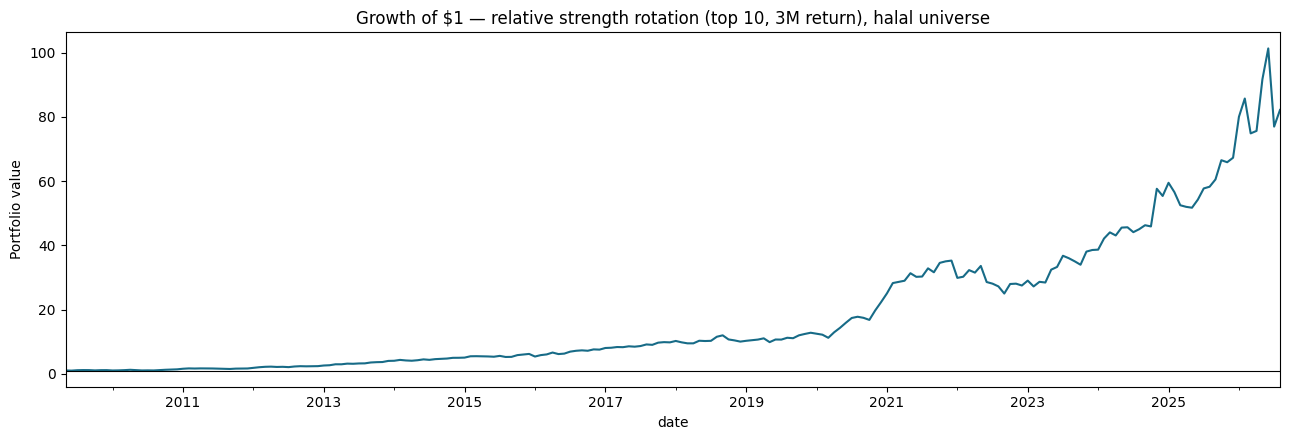

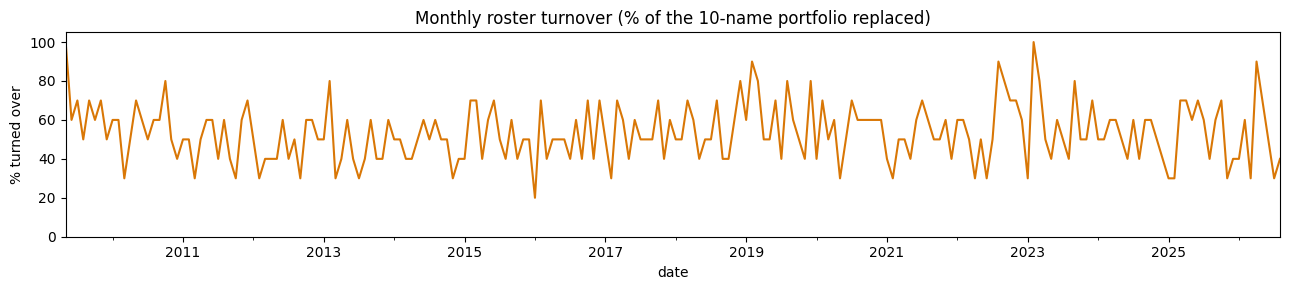

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.5))
wealth.plot(ax=ax, color='#176b87', title='Growth of $1 — relative strength rotation (top 10, 3M return), halal universe')
ax.set_ylabel('Portfolio value')
ax.axhline(1, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 3))
(turnover * 100).plot(ax=ax, color='#d97706', title='Monthly roster turnover (% of the 10-name portfolio replaced)')
ax.set_ylabel('% turned over')
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

## Monthly performance

Monthly returns of the relative strength rotation strategy.

In [9]:
table = (portfolio_returns * 100).rename('ret').to_frame()
table['year'] = table.index.year
table['month'] = table.index.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_table = table.pivot(index='year', columns='month', values='ret').reindex(columns=month_order)

annual_return = portfolio_returns.groupby(portfolio_returns.index.year).apply(lambda x: (1 + x).prod() - 1) * 100
monthly_table['Year'] = annual_return

monthly_summary = pd.Series({
    'months': len(portfolio_returns),
    'positive_months': int((portfolio_returns > 0).sum()),
    'pct_positive_months': float((portfolio_returns > 0).mean()),
    'avg_monthly_return': float(portfolio_returns.mean()),
    'median_monthly_return': float(portfolio_returns.median()),
    'best_month': portfolio_returns.idxmax().strftime('%Y-%m'),
    'best_month_return': float(portfolio_returns.max()),
    'worst_month': portfolio_returns.idxmin().strftime('%Y-%m'),
    'worst_month_return': float(portfolio_returns.min()),
})

styled = (
    monthly_table.round(1)
    .style.format(precision=1, na_rep='')
    .background_gradient(cmap='RdYlGn', axis=None, vmin=-15, vmax=15, subset=month_order)
    .set_caption('Monthly return (%) by year')
)
display(styled)
display(monthly_summary.to_frame('value'))

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Year
year,,,,,,,,,,,,,
2009,,,,,5.2,-4.6,12.7,3.6,-1.1,-7.5,6.7,0.8,15.4
2010,-9.4,3.2,6.6,9.3,-7.6,-9.0,2.5,-2.3,9.4,9.4,4.1,6.3,21.4
2011,13.1,6.8,-2.3,2.4,-0.6,-1.0,-3.0,-5.0,-1.4,7.2,2.2,0.6,19.1
2012,11.8,10.3,6.4,2.3,-4.3,2.0,-4.4,9.3,4.3,-1.8,1.6,0.8,43.6
2013,8.3,3.2,11.2,-0.2,7.0,-1.4,3.3,0.7,8.4,2.8,1.2,9.5,68.0
2014,1.1,6.6,-4.0,-2.1,3.9,6.3,-3.3,5.1,2.0,2.0,4.7,0.3,24.2
2015,1.1,8.2,0.5,-0.6,-0.9,-1.6,4.9,-6.1,0.6,10.3,3.3,3.0,24.0
2016,-13.1,8.2,3.7,9.6,-7.2,2.3,9.8,3.9,1.9,-1.7,5.9,-0.9,21.6
2017,6.7,0.9,2.7,-0.6,3.3,-1.4,2.4,5.7,-1.4,7.6,1.6,-0.7,29.9


,value
months,208
positive_months,135
pct_positive_months,0.649038
avg_monthly_return,0.023531
median_monthly_return,0.020138
best_month,2024-11
best_month_return,0.255484
worst_month,2026-07
worst_month_return,-0.240245


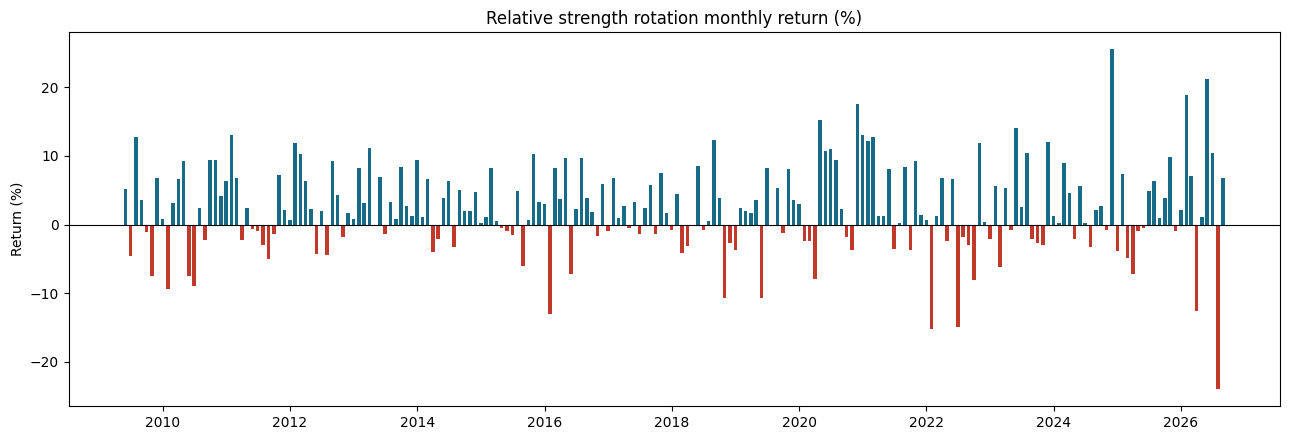

In [10]:
colors = np.where(portfolio_returns >= 0, '#176b87', '#c0392b')
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(portfolio_returns.index, portfolio_returns.values * 100, width=20, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Relative strength rotation monthly return (%)')
ax.set_ylabel('Return (%)')
plt.tight_layout()
plt.show()

## Caveats and next improvements

- **Look-ahead / survivorship bias in the universe**: `equities-list.csv` is today's list of halal
  candidates, projected backward. Stocks added or delisted over time aren't reconstructed
  point-in-time.
- **Price-only bars**: like the other notebooks, this uses IBKR `TRADES` bars — split-adjusted but
  not dividend-adjusted.
- **No transaction costs, and this is the notebook where that matters most**: a full top-10
  reshuffle most months means real commissions, spread, and market impact would take a much
  bigger bite out of this strategy's return than out of the pure momentum or trend-filter
  notebooks, which explicitly reduce turnover via a hold-band. The turnover chart above is there
  so you can see exactly how much trading this specification implies before assuming the backtest
  return is achievable net of costs.
- **Short, unskipped lookback**: a 3-month trailing return without a skip month is more exposed to
  short-term reversal effects (a stock that popped in the last few weeks can rank highly here in a
  way 12-1 momentum is specifically designed to avoid).
- **Concentration risk**: 10 equal-weighted names is a much more concentrated bet than the ~20-30
  names typically held by the other momentum notebooks — a single name's idiosyncratic move (an
  earnings miss, a halt) has an outsized effect on monthly returns.
- **Ranking universe drift**: many tickers (recent IPOs, in particular) don't have 4 months of
  history in earlier years and simply aren't eligible until they do; `MIN_UNIVERSE` guards against
  ranking with too few names but doesn't correct for the universe being thin in its earliest years.
- A serious version of this strategy would need a point-in-time halal screen, total-return prices,
  and realistic transaction costs modeled directly against the turnover series above — this is the
  notebook where costs are likely to matter most for whether the backtest is investable.